# code_064 · Spatial coordinates geometry and meshes

**Book:** section 13.3. A self-contained structure-preserving input laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_13_GUIDE.md), [run evidence](../CHAPTER_13_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_064).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1364;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1364


<a id="mesh"></a>
## Array rows do not define geometry

A six-node rectangular domain in metres is triangulated into four counterclockwise cells. Nodal temperature T=300+25*x+2*y K is a declared field, not a solved PDE. Cell thermal conductivities [10,10,20,20] W/(m K) belong to cells, not interchangeable node rows. Boundary tags 1/2 mean left/right; tag 0 means neither in this fixture. Store their dictionary, stable node IDs, coordinates, cell connectivity and location of each field separately. This is a finite-element-style input conversion, not a Gmsh parser or finite-element solver.


In [2]:
points=np.array([[0,0],[1,0],[2,0],[0,1],[1,1],[2,1]],dtype=float);cells=np.array([[0,1,4],[0,4,3],[1,2,5],[1,5,4]]);temperature=300+25*points[:,0]+2*points[:,1];tags=np.array([1,0,2,1,0,2]);conductivity=np.array([10,10,20,20.]);node_ids=np.array([101,205,310,401,508,612])
def signed_areas(P,C):
 a=P[C[:,1]]-P[C[:,0]];b=P[C[:,2]]-P[C[:,0]];return (a[:,0]*b[:,1]-a[:,1]*b[:,0])/2
areas=signed_areas(points,cells);assert np.all(areas>0) and np.isclose(areas.sum(),2.)
edges=np.array(sorted({tuple(sorted((int(a),int(b)))) for cell in cells for a,b in zip(cell,np.roll(cell,-1))}));lengths=np.linalg.norm(points[edges[:,1]]-points[edges[:,0]],axis=1);assert len(edges)==9 and np.all(lengths>0)
assert conductivity.shape==(len(cells),) and temperature.shape==(len(points),) and np.array_equal(node_ids[tags==1],[101,401])
integral=float(np.sum(areas*temperature[cells].mean(axis=1))) # exact integral for linear nodal field
perm=np.array([4,0,5,2,1,3]);inverse=np.argsort(perm);newcells=inverse[cells];newpoints=points[perm];newT=temperature[perm];newtags=tags[perm]
np.testing.assert_allclose(signed_areas(newpoints,newcells),areas);np.testing.assert_allclose(np.sum(signed_areas(newpoints,newcells)*newT[newcells].mean(axis=1)),integral);np.testing.assert_array_equal(node_ids[perm][newtags==1],node_ids[tags==1])
assert not np.allclose(signed_areas(newpoints,cells),areas) # invalid coordinates-only reordering
RESULTS['mesh']={'nodes':6,'triangles':4,'undirected_edges':len(edges),'area_m2':float(areas.sum()),'temperature_integral_K_m2':integral,'left_boundary_ids':node_ids[tags==1].tolist(),'right_boundary_ids':node_ids[tags==2].tolist(),'consistent_reindexing_passed':True}


<a id="frames"></a>
## Transform the coordinate frame and vector quantities consistently

Rotate coordinates by 30 degrees and translate their origin. Temperature is a scalar and stays attached to the same physical node. Its gradient is a vector in K/m and rotates with the frame. Pairwise edge lengths and oriented areas are invariant under this proper rigid rotation. A reflection would reverse orientation unless connectivity is adjusted; dropping points requires a new valid mesh rather than reusing old cell indices. Boundary membership remains attached to IDs, not re-inferred from the minimum new x coordinate.


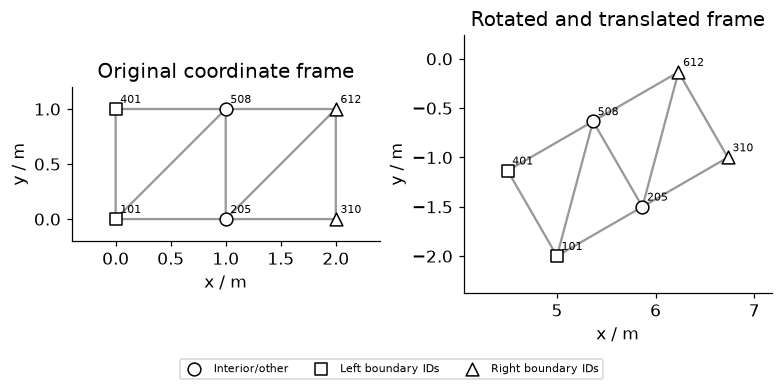

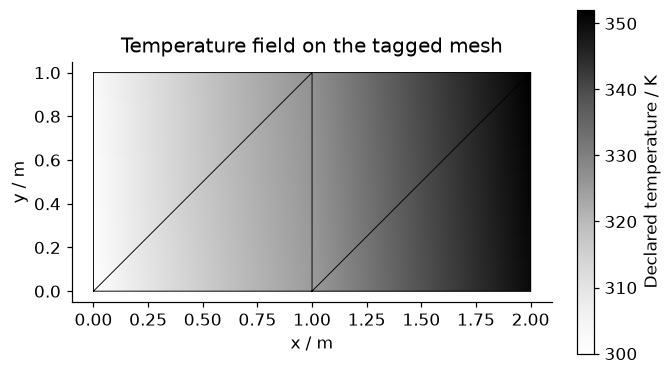

In [3]:
a=np.pi/6;R=np.array([[np.cos(a),-np.sin(a)],[np.sin(a),np.cos(a)]]);rotated=points@R.T+np.array([5,-2]);gradient=np.array([25.,2.]);newgradient=R@gradient
np.testing.assert_allclose(np.linalg.norm(rotated[edges[:,1]]-rotated[edges[:,0]],axis=1),lengths);np.testing.assert_allclose(signed_areas(rotated,cells),areas)
np.testing.assert_allclose((rotated-rotated[0])@newgradient,temperature-temperature[0]);RESULTS['rotated_gradient_K_per_m']=newgradient.tolist();RESULTS['rigid_frame_checks_passed']=True
fig,axes=plt.subplots(1,2,figsize=(7,3.4))
for ax,P,title in zip(axes,[points,rotated],['Original coordinate frame','Rotated and translated frame']):
 ax.triplot(P[:,0],P[:,1],cells,color='.6')
 for tag,marker,label in [(0,'o','Interior/other'),(1,'s','Left boundary IDs'),(2,'^','Right boundary IDs')]:
  take=tags==tag;ax.scatter(P[take,0],P[take,1],marker=marker,s=70,facecolors='white',edgecolors='black',label=label)
 for j in range(6):ax.annotate(str(node_ids[j]),P[j],xytext=(3,4),textcoords='offset points',fontsize=7)
 ax.set(title=title,aspect='equal',xlabel='x / m',ylabel='y / m');ax.margins(.2)
handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,fontsize=7,loc='lower center',bbox_to_anchor=(.5,-.08),ncol=3);plt.show()
fig,ax=plt.subplots(figsize=(6,3.3));plot=ax.tripcolor(points[:,0],points[:,1],cells,temperature,cmap='Greys',shading='gouraud');ax.triplot(points[:,0],points[:,1],cells,color='black',lw=.6);fig.colorbar(plot,ax=ax,label='Declared temperature / K');ax.set(aspect='equal',xlabel='x / m',ylabel='y / m',title='Temperature field on the tagged mesh');plt.show()


In [4]:
summary={'example_id':'code_064','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['points cells edges and material fields', 'boundary tags and scalar vector units', 'consistent mesh renumbering', 'coordinate frames and field transformations'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["points cells edges and material fields", "boundary tags and scalar vector units", "consistent mesh renumbering", "coordinate frames and field transformations"], "elapsed_seconds": 0.177, "example_id": "code_064", "hardware": "Darwin arm64 CPU", "results": {"mesh": {"area_m2": 2.0, "consistent_reindexing_passed": true, "left_boundary_ids": [101, 401], "nodes": 6, "right_boundary_ids": [310, 612], "temperature_integral_K_m2": 652.0, "triangles": 4, "undirected_edges": 9}, "rigid_frame_checks_passed": true, "rotated_gradient_K_per_m": [20.65063509461097, 14.232050807568875]}, "seed": 1364, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
